In [70]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [71]:
df = pd.read_csv ('Superstore.csv', encoding='ISO-8859-1')

In [72]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [73]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

In [74]:
df.duplicated().sum()

np.int64(0)

In [75]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [76]:
df['Category'].value_counts()

Category
Office Supplies    6026
Furniture          2121
Technology         1847
Name: count, dtype: int64

[Text(0, -20, '836,154'), Text(0, -20, '742,000'), Text(0, -20, '719,047')]

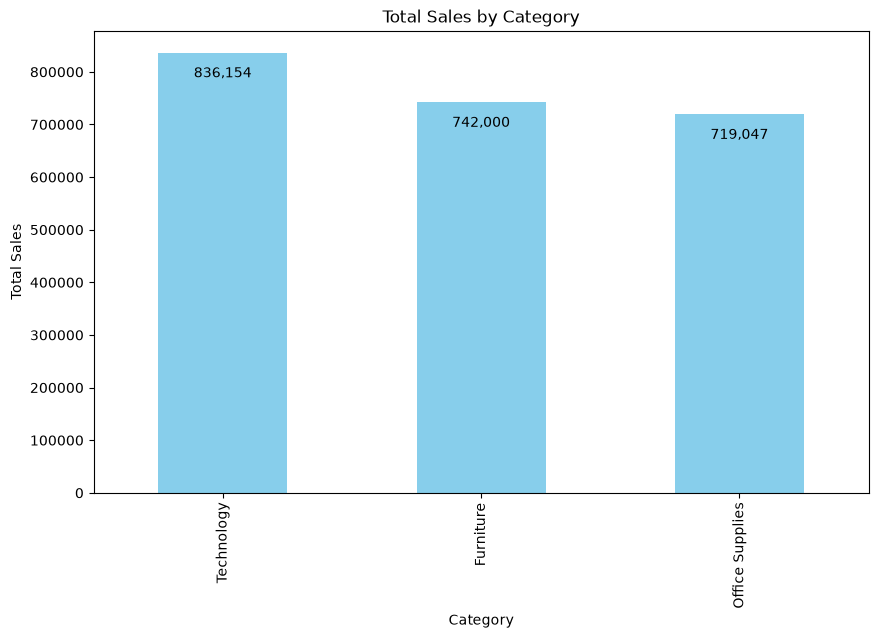

In [77]:
# Group by category and sum the sales
category_sales = df.groupby('Category')['Sales'].sum()

# Option 1: Sort to find the highest-selling category
top_category = category_sales.sort_values(ascending=False)
ax = top_category.plot (kind='bar', title='Total Sales by Category', ylabel='Total Sales', xlabel='Category', color='skyblue', figsize=(10, 6))
ax.bar_label(ax.containers[0], padding = -20, fmt='{:,.0f}' )

[Text(0, -20, '915'), Text(0, -20, '747'), Text(0, -20, '537')]

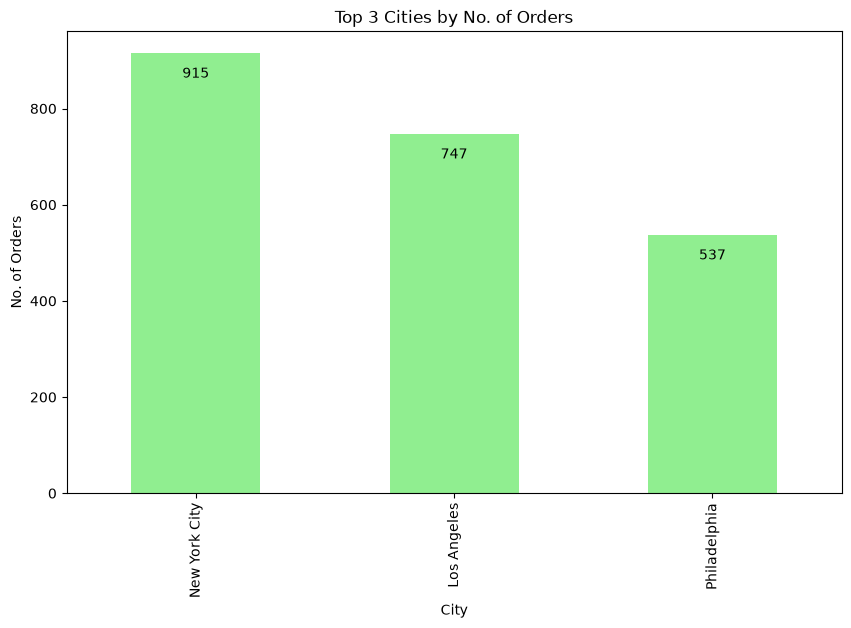

In [78]:
top_cities = df.City.value_counts().head(3)
ax = top_cities.plot(kind='bar',title='Top 3 Cities by No. of Orders',ylabel='No. of Orders',xlabel='City',color='lightgreen',figsize=(10, 6),)
ax.bar_label(ax.containers[0], padding=-20)



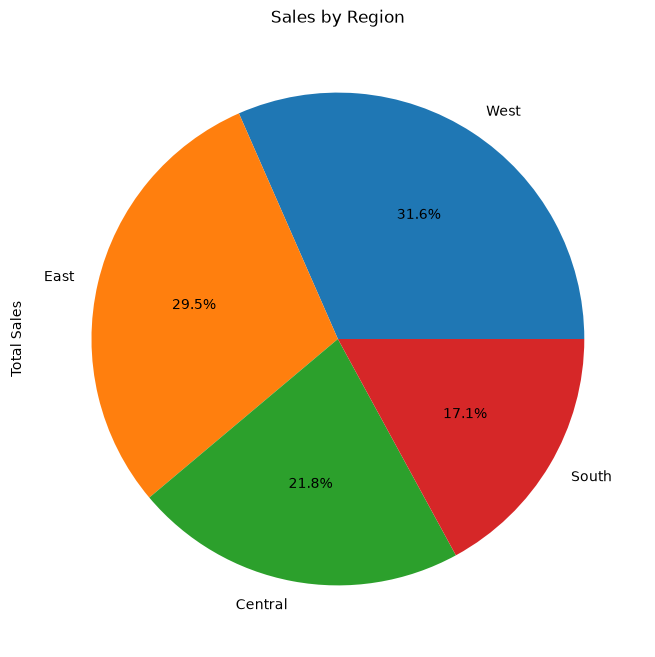

In [96]:
region_sales = df.groupby('Region')['Sales'].sum().astype(int).sort_values(ascending=False)
ax = region_sales.plot(kind='pie', title='Sales by Region', ylabel='Total Sales', figsize=(8, 8),autopct='%1.1f%%', )


[Text(0, -20, '25043'),
 Text(0, -20, '19052'),
 Text(0, -20, '15117'),
 Text(0, -20, '14595'),
 Text(0, -20, '14473')]

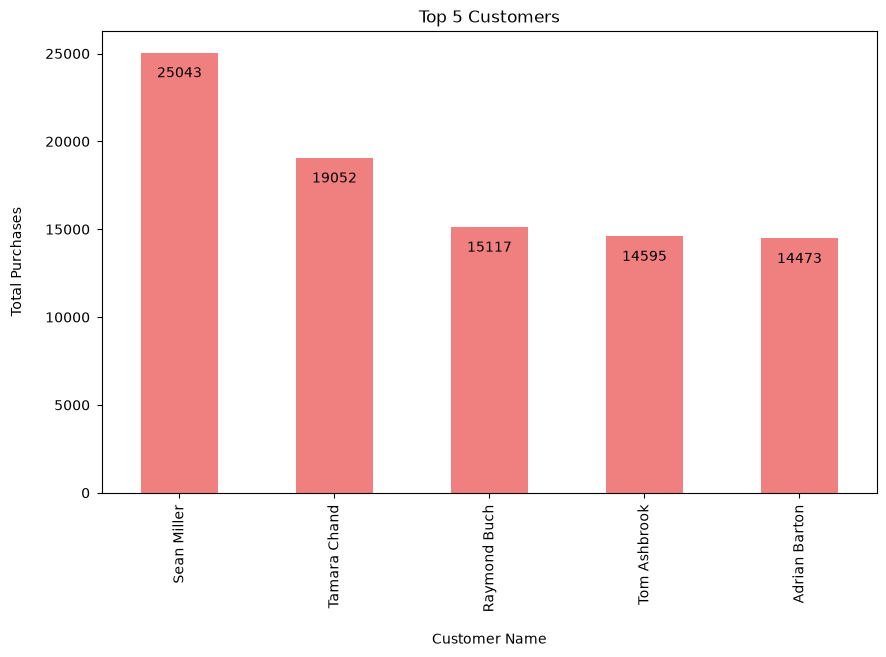

In [189]:

top_customers = df.groupby('Customer Name')['Sales'].sum().sort_values(ascending=False).head(5).astype(int)
ax = top_customers.plot(kind ='bar', title='Top 5 Customers', color='lightcoral', figsize=(10, 6))
ax.set_xlabel('Customer Name', labelpad=15)
ax.set_ylabel('Total Purchases', labelpad=15)
ax.tick_params(axis='both', pad=5)
ax.bar_label(ax.containers[0], padding = -20,color='black')

In [171]:

top_customers = df.groupby('Customer ID')['Sales'].sum().sort_values(ascending=False).head(10)
top_customers

Customer ID
SM-20320    25043.050
TC-20980    19052.218
RB-19360    15117.339
TA-21385    14595.620
AB-10105    14473.571
KL-16645    14175.229
SC-20095    14142.334
HL-15040    12873.298
SE-20110    12209.438
CC-12370    12129.072
Name: Sales, dtype: float64

[Text(0, -20, '25199'),
 Text(0, -20, '7753'),
 Text(0, -20, '6983'),
 Text(0, -20, '4570'),
 Text(0, -20, '4094')]

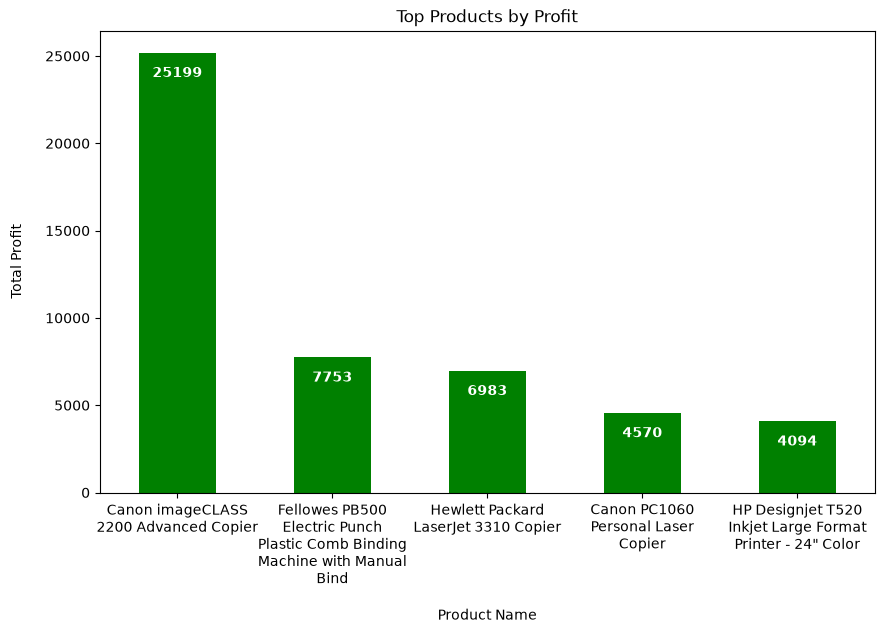

In [194]:
import textwrap

product_profit = df.groupby('Product Name')['Profit'].sum().sort_values(ascending=False).head(5).astype(int)
ax =product_profit.plot(kind='bar',title = 'Top Products by Profit',figsize=(10,6), color = 'green')
ax.set_xlabel('Product Name', labelpad=15)
ax.set_ylabel('Total Profit', labelpad=15)
# Wrap long product names
ax.set_xticklabels([
    textwrap.fill(label.get_text(), width=20)
    for label in ax.get_xticklabels()
], rotation=0, ha='center')
ax.bar_label(ax.containers[0], padding = -20,color='white',weight = 'bold')



[Text(0, 20, '-9239'),
 Text(0, 20, '-6859'),
 Text(0, 20, '-5269'),
 Text(0, 20, '-5098'),
 Text(0, 20, '-4162')]

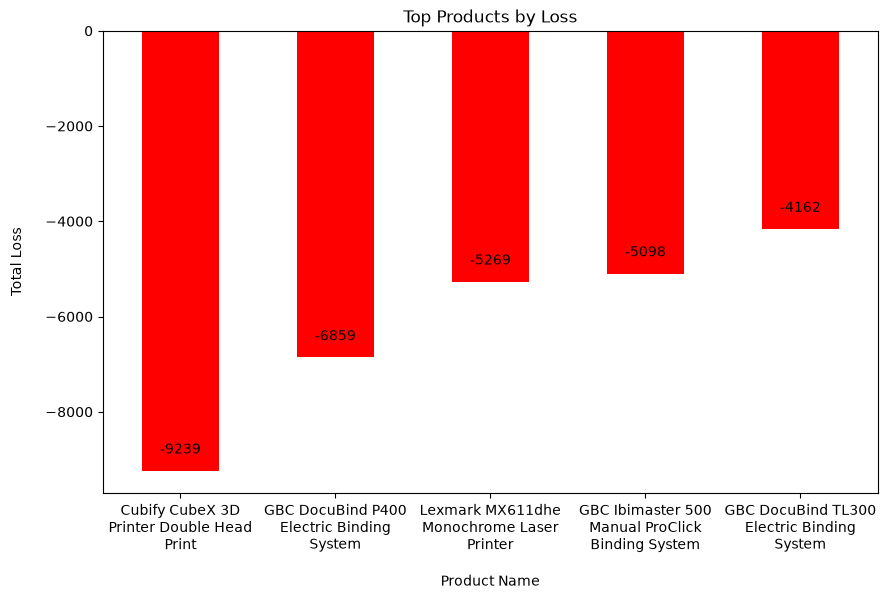

In [222]:
import textwrap

product_loss = df[df['Profit'] < 0].groupby('Product Name')['Profit'].sum().sort_values(ascending=True).head(5).astype(int)
ax =product_loss.plot(kind='bar',title = 'Top Products by Loss',figsize=(10,6), color = 'red')
ax.set_xlabel('Product Name', labelpad=15)
ax.set_ylabel('Total Loss', labelpad=15)
# Wrap long product names
ax.set_xticklabels([
    textwrap.fill(label.get_text(), width=20)
    for label in ax.get_xticklabels()
], rotation=0, ha='center')
ax.bar_label(ax.containers[0], padding = -20,color='black')

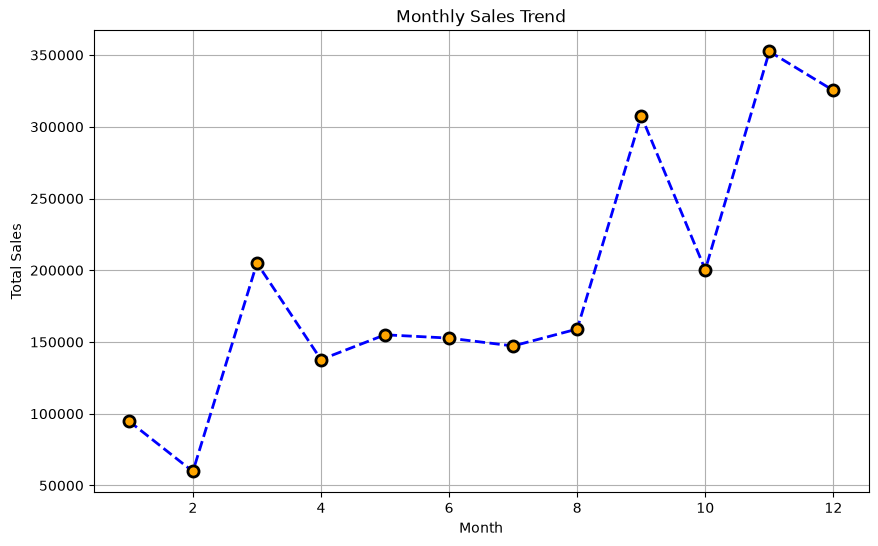

In [254]:
df['Month'] = df['Order Date'].dt.month
month_sales = df.groupby('Month')['Sales'].sum().astype(int)
ax = month_sales.plot(kind='line', title='Monthly Sales Trend',ylabel = 'Total Sales',xlabel = 'Month', color='blue', marker='o', figsize=(10, 6), grid=True, linestyle='--', linewidth=2, markersize=8, markerfacecolor='orange', markeredgewidth=2, markeredgecolor='black')



[Text(0, 0, 'Jan'),
 Text(1, 0, 'Feb'),
 Text(2, 0, 'Mar'),
 Text(3, 0, 'Apr'),
 Text(4, 0, 'May'),
 Text(5, 0, 'Jun'),
 Text(6, 0, 'Jul'),
 Text(7, 0, 'Aug'),
 Text(8, 0, 'Sep'),
 Text(9, 0, 'Oct'),
 Text(10, 0, 'Nov'),
 Text(11, 0, 'Dec')]

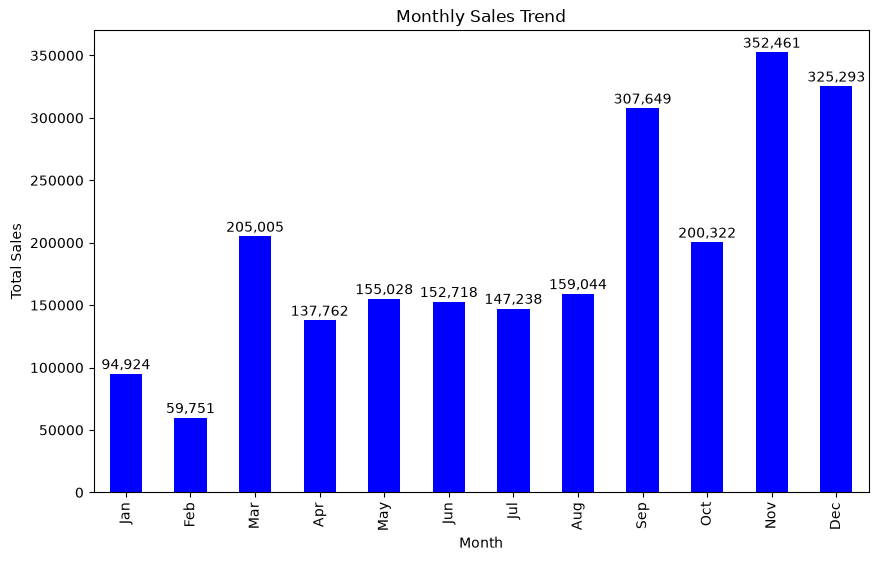

In [255]:
df['Month'] = df['Order Date'].dt.month
month_sales = df.groupby('Month')['Sales'].sum().astype(int)
ax = month_sales.plot(kind='bar', title='Monthly Sales Trend',ylabel = 'Total Sales',xlabel = 'Month', color='blue', figsize=(10, 6))
ax.bar_label(ax.containers[0], padding = 1, fmt='{:,.0f}')
ax.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])

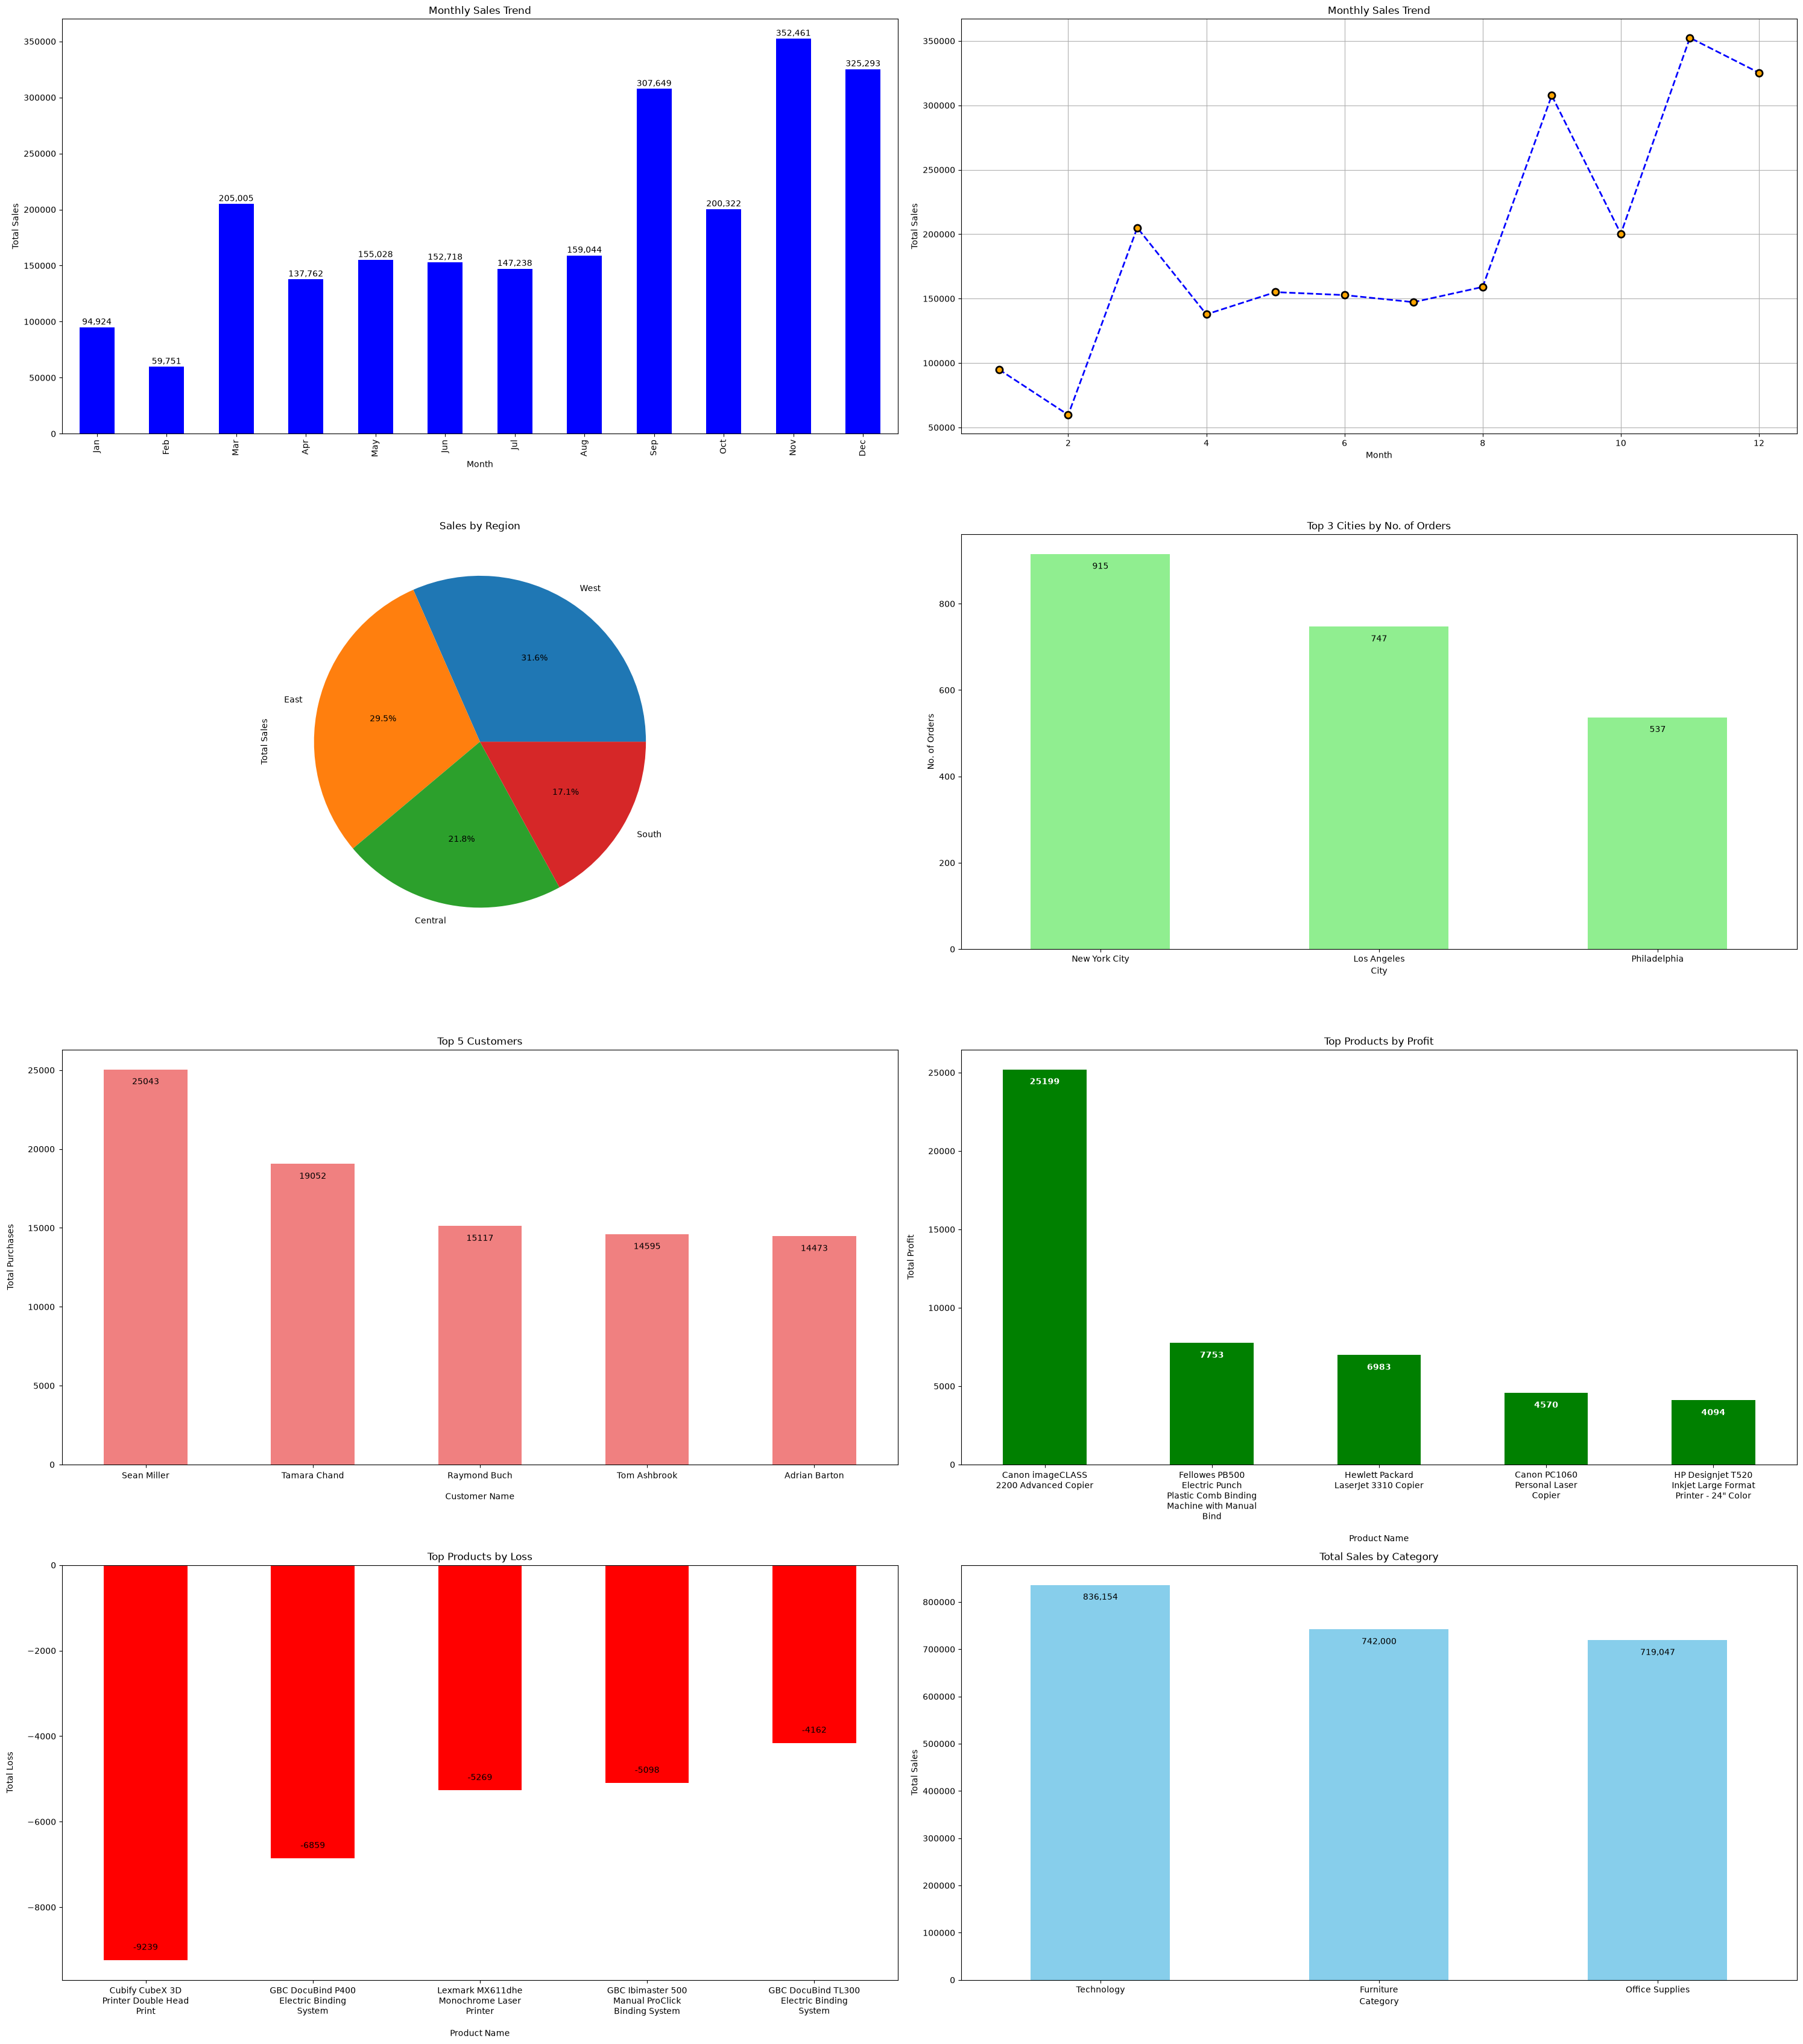

In [291]:
# SECTION 11: Visualizations
fig, axes = plt.subplots(4, 2, figsize=(30, 34))

# Monthly Sales Trend
month_sales = df.groupby('Month')['Sales'].sum().astype(int)
ax = month_sales.plot(kind='bar', title='Monthly Sales Trend',ylabel = 'Total Sales',xlabel = 'Month', color='blue', ax=axes[0, 0])
ax.bar_label(ax.containers[0], padding = 1, fmt='{:,.0f}')
ax.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])

# Monthly Sales Trend (Line Chart)
df['Month'] = df['Order Date'].dt.month
month_sales = df.groupby('Month')['Sales'].sum().astype(int)
ax = month_sales.plot(kind='line', title='Monthly Sales Trend',ylabel = 'Total Sales',xlabel = 'Month', color='blue',ax=axes[0, 1], marker='o', grid=True, linestyle='--', linewidth=2, markersize=8, markerfacecolor='orange', markeredgewidth=2, markeredgecolor='black')


# Sales by Region
region_sales = df.groupby('Region')['Sales'].sum().astype(int).sort_values(ascending=False)
ax = region_sales.plot(kind='pie', title='Sales by Region', ylabel='Total Sales', ax=axes[1, 0], autopct='%1.1f%%')

# Top 3 Cities by No. of Orders
top_cities = df.City.value_counts().head(3)
ax = top_cities.plot(kind='bar',title='Top 3 Cities by No. of Orders',ylabel='No. of Orders',xlabel='City',color='lightgreen', ax=axes[1,1])
ax.bar_label(ax.containers[0], padding=-20)
ax.set_xticklabels(top_cities.index, rotation=0, ha='center')

# Top 5 Customers
top_customers = df.groupby('Customer Name')['Sales'].sum().sort_values(ascending=False).head(5).astype(int)
ax = top_customers.plot(kind ='bar', title='Top 5 Customers', color='lightcoral', ax=axes[2, 0])
ax.set_xlabel('Customer Name', labelpad=15)
ax.set_ylabel('Total Purchases', labelpad=15)
ax.tick_params(axis='both', pad=5)
ax.bar_label(ax.containers[0], padding = -20,color='black')
ax.set_xticklabels(top_customers.index, rotation=0, ha='center')

# Top Products by Profit
import textwrap
product_profit = df.groupby('Product Name')['Profit'].sum().sort_values(ascending=False).head(5).astype(int)
ax =product_profit.plot(kind='bar',title = 'Top Products by Profit',ax=axes[2, 1], color = 'green')
ax.set_xlabel('Product Name', labelpad=15)
ax.set_ylabel('Total Profit', labelpad=15)
# Wrap long product names
ax.set_xticklabels([
    textwrap.fill(label.get_text(), width=20)
    for label in ax.get_xticklabels()
], rotation=0, ha='center')
ax.bar_label(ax.containers[0], padding = -20,color='white',weight = 'bold')

# Top Products by Loss
product_loss = df[df['Profit'] < 0].groupby('Product Name')['Profit'].sum().sort_values(ascending=True).head(5).astype(int)
ax =product_loss.plot(kind='bar',title = 'Top Products by Loss',ax=axes[3, 0], color = 'red')
ax.set_xlabel('Product Name', labelpad=15)
ax.set_ylabel('Total Loss', labelpad=15)
# Wrap long product names
ax.set_xticklabels([
    textwrap.fill(label.get_text(), width=20)
    for label in ax.get_xticklabels()
], rotation=0, ha='center')
ax.bar_label(ax.containers[0], padding = -20,color='black')

# Total Sales by Category
category_sales = df.groupby('Category')['Sales'].sum()
top_category = category_sales.sort_values(ascending=False)
ax = top_category.plot (kind='bar', title='Total Sales by Category', ylabel='Total Sales', xlabel='Category', color='skyblue', ax=axes[3, 1])
ax.bar_label(ax.containers[0], padding = -20, fmt='{:,.0f}' )
ax.set_xticklabels(top_category.index, rotation=0, ha='center')

plt.tight_layout()
plt.savefig('sales_analysis.png')

In [256]:
plt.savefig('sales_analysis.png')

<Figure size 640x480 with 0 Axes>

Shape: (9994, 21)

Column names:
 ['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Data types:
 Row ID             int64
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code        int64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object

First 5 rows:
    Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0       1  CA-2016-152156   11/8/2016  11/11/2016    Sec

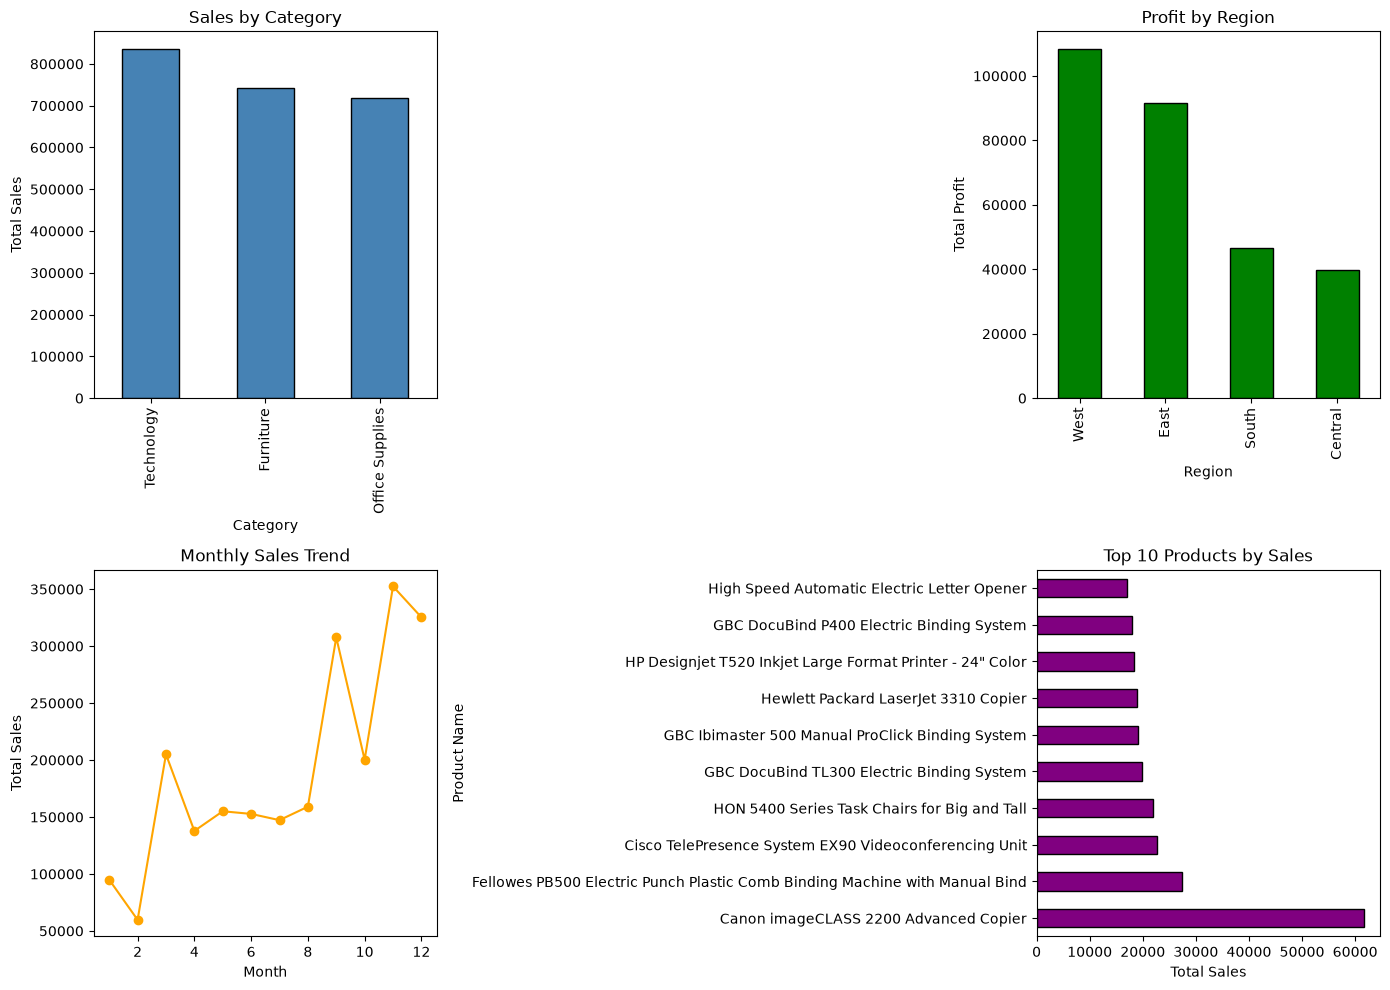


Analysis complete. Chart saved.


In [80]:
# SECTION 1: Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# SECTION 2: Load data
df = pd.read_csv('Superstore.csv', encoding='latin1')

# SECTION 3: First look
print("Shape:", df.shape)
print("\nColumn names:\n", df.columns.tolist())
print("\nData types:\n", df.dtypes)
print("\nFirst 5 rows:\n", df.head())

# SECTION 4: Data quality check
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nBasic statistics:\n", df.describe())

# SECTION 5: Data cleaning
df.drop_duplicates(inplace=True)
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])

# SECTION 6: Analysis — Category
category_sales = df.groupby('Category')['Sales'].sum().sort_values(ascending=False)
category_profit = df.groupby('Category')['Profit'].sum().sort_values(ascending=False)
print("\nSales by Category:\n", category_sales)
print("\nProfit by Category:\n", category_profit)

# SECTION 7: Analysis — Region
region_profit = df.groupby('Region')['Profit'].sum().sort_values(ascending=False)
region_sales = df.groupby('Region')['Sales'].sum().sort_values(ascending=False)
print("\nProfit by Region:\n", region_profit)

# SECTION 8: Monthly trend
df['Month'] = df['Order Date'].dt.month
monthly_sales = df.groupby('Month')['Sales'].sum()
print("\nMonthly Sales:\n", monthly_sales)

# SECTION 9: Top 10 products
top_products = df.groupby('Product Name')['Sales'].sum().nlargest(10)
print("\nTop 10 Products:\n", top_products)

# SECTION 10: Find loss-making products
loss_products = df[df['Profit'] < 0].groupby('Product Name')['Profit'].sum().nsmallest(5)
print("\nTop 5 Loss-Making Products:\n", loss_products)

# SECTION 11: Visualizations
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

category_sales.plot(kind='bar', ax=axes[0,0],
                    title='Sales by Category',
                    color='steelblue', edgecolor='black')
axes[0,0].set_xlabel('Category')
axes[0,0].set_ylabel('Total Sales')

region_profit.plot(kind='bar', ax=axes[0,1],
                   title='Profit by Region',
                   color='green', edgecolor='black')
axes[0,1].set_xlabel('Region')
axes[0,1].set_ylabel('Total Profit')

monthly_sales.plot(ax=axes[1,0],
                   title='Monthly Sales Trend',
                   color='orange', marker='o')
axes[1,0].set_xlabel('Month')
axes[1,0].set_ylabel('Total Sales')

top_products.plot(kind='barh', ax=axes[1,1],
                  title='Top 10 Products by Sales',
                  color='purple', edgecolor='black')
axes[1,1].set_xlabel('Total Sales')

plt.tight_layout()
plt.savefig('sales_analysis.png')
plt.show()

print("\nAnalysis complete. Chart saved.")